<a href="https://colab.research.google.com/github/natsukosugimura/DeepLearning2/blob/main/2026_python_tutorial_dl_day2_omake.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

カラー画像の識別をTensorFlowで実装してみる
畳み込み、プーリング、畳み込み、プーリングで

ネットから自分でデータセットを取得してみる


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from datasets import load_dataset

# CIFAR-10 データセットの読み込み（カラー画像）
# 公式配布元（cs.toronto.edu）が非常に遅いため、HF のミラーから取得して keras と同じ形式に変換する
ds = load_dataset("uoft-cs/cifar10").with_format("numpy")

def to_keras(split):
    d = ds[split][:]
    return d["img"].astype(np.uint8), d["label"].astype(np.uint8).reshape(-1, 1)

(x_train, y_train), (x_test, y_test) = to_keras("train"), to_keras("test")

### CIFAR-10(シーファー テン)とは？
CIFAR-10 (https://www.cs.toronto.edu/~kriz/cifar.html)

カラー画像のデータセットで，(32,32,3)の3次元データです．つまり，RGBの色情報を持つ32x32の画像データです．

CIFAR-10のラベルは以下の通りです．
- **ラベル「0」**： airplane（飛行機）
- **ラベル「1」**： automobile（自動車）
- **ラベル「2」**： bird（鳥）
- **ラベル「3」**： cat（猫）
- **ラベル「4」**： deer（鹿）
- **ラベル「5」**： dog（犬）
- **ラベル「6」**： frog（カエル）
- **ラベル「7」**： horse（馬）
- **ラベル「8」**： ship（船）
- **ラベル「9」**： truck（トラック）

In [ ]:
#x_trainの形状を表示
x_train.shape

In [ ]:
#x_trainの先頭1つを表示
x_train[0]


In [ ]:
#画像を何枚か表示する
import matplotlib.pyplot as plt

# 表示する画像の数
num_images = 10

# 表示する画像のインデックス
image_indices = range(num_images)

# 表示する画像を選択
selected_images = x_train[image_indices]

# 表示する画像を表示
for i, image in enumerate(selected_images):
    plt.subplot(1, num_images, i + 1)
    plt.imshow(image)
    plt.axis('off')
plt.show()



In [ ]:
#ラベルを表示
print(y_train[image_indices])


In [ ]:
x_train

In [ ]:
# 画像の正規化: [0, 255] -> [0.0, 1.0]
x_train = x_train.astype('float32') / 255.0
x_test  = x_test.astype('float32')  / 255.0

In [ ]:
# モデルの構築
model = models.Sequential([
    # ブロック1: 畳み込み層とプーリング層
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # ブロック2: 畳み込み層とプーリング層
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # 平坦化層
    layers.Flatten(),

    # 全結合層
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')  # CIFAR-10 は10クラス分類
])

# モデルのコンパイル
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# モデル概要の表示
model.summary()

In [ ]:
# 学習の実行
history = model.fit(x_train, y_train, epochs=15, batch_size=256,
                    validation_data=(x_test, y_test))

In [ ]:
from pandas import DataFrame
# accuracyとlossの推移を確認
DataFrame({'accuracy': history.history['accuracy'],
           'val_accuracy': history.history['val_accuracy']}).plot()
DataFrame({'loss': history.history['loss'],
           'val_loss': history.history['val_loss']}).plot()

In [ ]:
# テストデータでの評価
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print("Test accuracy:", test_acc)

自分で用意した画像を判別させてみる

In [ ]:
# 自分で用意した画像を読み込み、リサイズして判別する処理

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 判別したい画像のパス（適宜ご自身の画像のパスに変更してください）
image_path = 'car.jpg'


# 画像をBGR形式で読み込む
img = cv2.imread(image_path)
if img is None:
    print("画像の読み込みに失敗しました。パスを確認してください。")
else:
    # BGRからRGBへ変換（matplotlibで正しく表示するため）
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 元の画像を表示
    plt.imshow(img_rgb)
    plt.title('元の画像')
    plt.axis('off')
    plt.show()

    # 画像を32x32にリサイズ
    img_resized = cv2.resize(img_rgb, (32, 32))

    # リサイズ後の画像を表示
    plt.imshow(img_resized)
    plt.title('リサイズ後の画像 (32x32)')
    plt.axis('off')
    plt.show()

    # 画像の正規化: [0, 255] -> [0.0, 1.0]
    img_normalized = img_resized.astype('float32') / 255.0

    # バッチ次元を追加して、入力の形状を (1, 32, 32, 3) にする
    img_input = np.expand_dims(img_normalized, axis=0)

    # モデルによる予測
    predictions = model.predict(img_input)
    predicted_class = np.argmax(predictions, axis=-1)[0]

    # CIFAR-10 のラベルマッピング（必要に応じて変更してください）
    label_mapping = {
        0: "airplane",
        1: "automobile",
        2: "bird",
        3: "cat",
        4: "deer",
        5: "dog",
        6: "frog",
        7: "horse",
        8: "ship",
        9: "truck",
    }

    # 予測結果の表示
    print(f"予測されたラベル: {predicted_class}")
    print(f"ラベルの意味: {label_mapping[predicted_class]}")




In [ ]:
#出力が各ラベルに対してどのくらいの確率であるかを表示
print(f"予測されたラベル: {predictions}")

#出力をラベルごとにグラフで表示（各ラベルを表示）
plt.bar(label_mapping.values(), predictions[0])
plt.xticks(rotation=90)
plt.show()

## おまけ

### 深層学習入門者におすすめの書籍

- [ゼロから作るDeep Learning](https://www.oreilly.co.jp/books/9784873117584/)
  - 名前の通り、TensorFlowなどの深層学習ライブラリに頼らず深層学習を実装することで、原理から深層学習を理解することができる。
- [TensorFlowとKerasで動かしながら学ぶディープラーニングの仕組み](https://book.mynavi.jp/ec/products/detail/id=109925)
  - 主にCNNを題材にして、TensorFlow/Kerasを用いて実装されたソースコードと共に、ニューラルネットワークがどのように学習および推論しているのかを理解することができる。

### Pythonを使うための準備

#### Python環境

##### Pythonの環境とは
- 主にPythonのバージョンとインストールされたライブラリから成る

##### Python環境構築手法

- [Google Colaboratory](https://colab.research.google.com)
  - 今まさに使っているもの
  - ブラウザ上で完結する
  - 一番手軽ではあるが実務には向かない
- [Python公式サイト](https://www.python.org/downloads/) からPCまたはサーバにPythonをダウンロード
- [Docker](https://hub.docker.com/_/python)
  - Anacondaなどよりも根本から環境を切り分けるので、ホスト環境にほとんど依存せず、より安全に環境を構築・管理できる
  - 環境の構成をDockerfile(とdocker-compose.yml)というファイルとして定義することで、環境の再現性・再利用性がかなり高くなる
  - 複数の環境を共存させる場合には個人的に一番理想的な構築手法
  - [Docker](https://www.docker.com/)の使い方を学ぶ必要がある

#### エディタ/IDE

##### エディタ/IDEとは
- エディタ：ソースコードの編集を行うツール
- IDE：エディタの機能に加えて実行・デバッグなどの機能を提供するツール

##### よく使われるエディタ/IDE
- [Visual Studio Code (VS Code)](https://code.visualstudio.com/)
  - 多くの人に使われているエディタ / IDE
  - Python 以外のプログラミング言語もサポートしている
  - 拡張機能で AI の補完も追加できる
- [Jupyter Notebook](https://jupyter.org/)
  - 対話形式でコードを実行できる
  - 大規模なプロジェクトには向かない
  - Google Colaboratory は、クラウド上に Jupyter Notebook の環境を用意して提供している
- [Cursor](https://www.cursor.com/)
  - 操作の土台は VS Code と同じエディタ
  - コード補完に加えて、チャットの指示で複数のファイルを直し、ターミナルでコマンドも実行できる

# 転移学習を使った自前のデータセットの分類

学習済みの MobileNetV2 を用いて、自前の写真をラーメンとカレーに分類します。
MNIST や CIFAR-10 を用いた学習時のように畳み込み層を初期値から学習するのではなく、ImageNet で学習した重みを用い、まず分類層だけを学習し、その後に後方の層を更新します。

このノートにはデータセットを同梱していません。ご自身で作成していただくか、[こちらのリンク](https://drive.google.com/drive/folders/1v8HUFScRsmfiqI8BLRUMz_nX4n_NppW5?usp=drive_link)のデータセットをマイドライブに置くことで、転移学習を実行できます。

## 全体像

ここでは、転移学習を使ってラーメンとカレーを分類します。
入力として写真を入れると、モデルは二つの確率を出力するため、大きいほうのクラスを予測とします。

### 転移学習とは

転移学習とは、別の課題ですでに学習した重みを、今回の初期値として使うことです。
これまで扱った重みは、入力をどう変換するかを決める数値です。
ランダムな値から始めると、この数値をすべて自分の用意した写真だけで決めることになります。
このノートでは、ImageNet で学習済みの MobileNetV2 を使用します。
ImageNet とは、約120万枚の写真を1000クラスに分ける課題です。

### なぜ有用か

各クラス数十枚では、写真の見分け方を初期値から学習するのが難しいためです。
MNIST は形が限られていて、学習用が6万枚あるため、重みをランダムな値から学習できました。
今回の写真は色があり、角度や明るさや皿も写真ごとに変わります。しかし、各クラスは数十枚しかありません。
畳み込み層をこの枚数で初期値から学習すると、線や色や模様の情報を獲得する前に、学習用の写真へ過剰に適合してしまい、過学習を起こしてしまいます。

ImageNet の学習済みモデルでは、その見分け方をすでに獲得しており、MobileNetV2 の前方の層は、線の向き、色の塊、模様、物体の境界に対応する重みを持っています。
1000クラスの中にラーメンやカレーはありませんが、入力は同じ種類の写真であるため、線や境界の特徴を組み合わせて、お碗や麺や皿の縁を表現することができます。

この重みを使用しますが、実際には2クラスへ分類を行います。
そのための設定として `include_top=False` があり、これは1000クラス用の分類層を外す指定です。
外した位置に、ラーメンとカレー用の `Dense(2, softmax)` を追加します。
新しく決める重みは MobileNetV2 全体より少ないので、数十枚の訓練用データでも2クラスを分ける規則を学習できます。

### 処理の流れ

1. 入力は、`マイドライブ/data/ramen` と `マイドライブ/data/curry` です。フォルダ名が正解ラベルになります。8割を train、2割を test にします。
2. 前処理では、写真を 224×224 にそろえ、`preprocess_input` で画素値の範囲を変換します。学習用のデータだけ、左右反転、小さい回転、ズーム、平行移動を加えます。撮った状態の写真で精度を測るため、testのデータに対しては行いません。
3. MobileNetV2 は、第1段階では ImageNet で獲得した特徴抽出をそのまま使います。第2段階では、後方の層だけを小さい学習率で更新します。
4. 分類層では、特徴を1本のベクトルにまとめたあと、`Dropout(0.3)` と `Dense(2, softmax)` で和が1になるように二つの確率を出します。


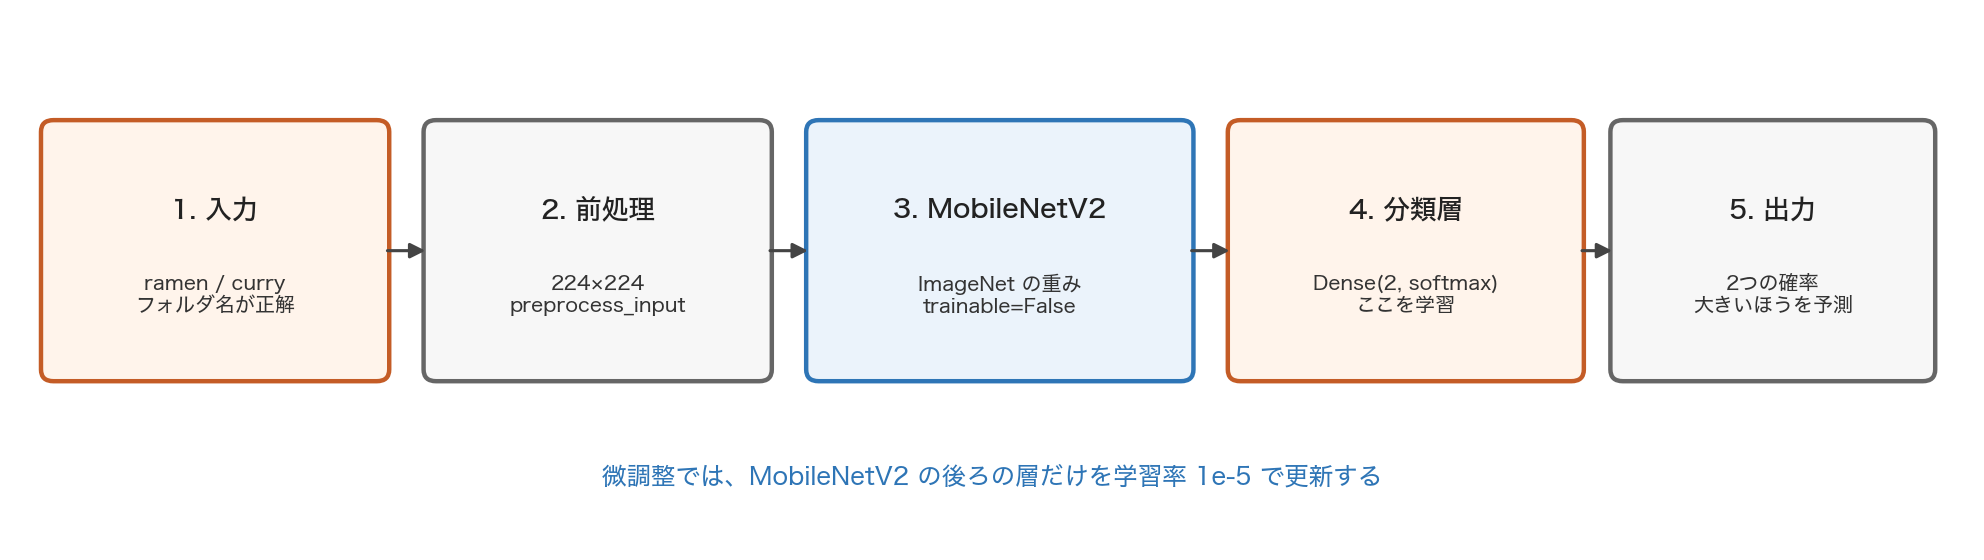


### 学習の進め方

全部の重みを最初から大きく更新すると、ImageNet で得た特徴が失われます。
そのため、学習は二段階で行います。
まず `trainable=False` で MobileNetV2 を固定し、分類層だけを8 epoch 学習します。
次に、料理の違いに関係しやすい後方の層だけを学習可能に戻し、学習率 `1e-5` で4 epoch 学習します。
この学習率は、分類層のときの `1e-3` の100分の1です。更新幅を小さくし、獲得済みの特徴を大きく変えないためです。

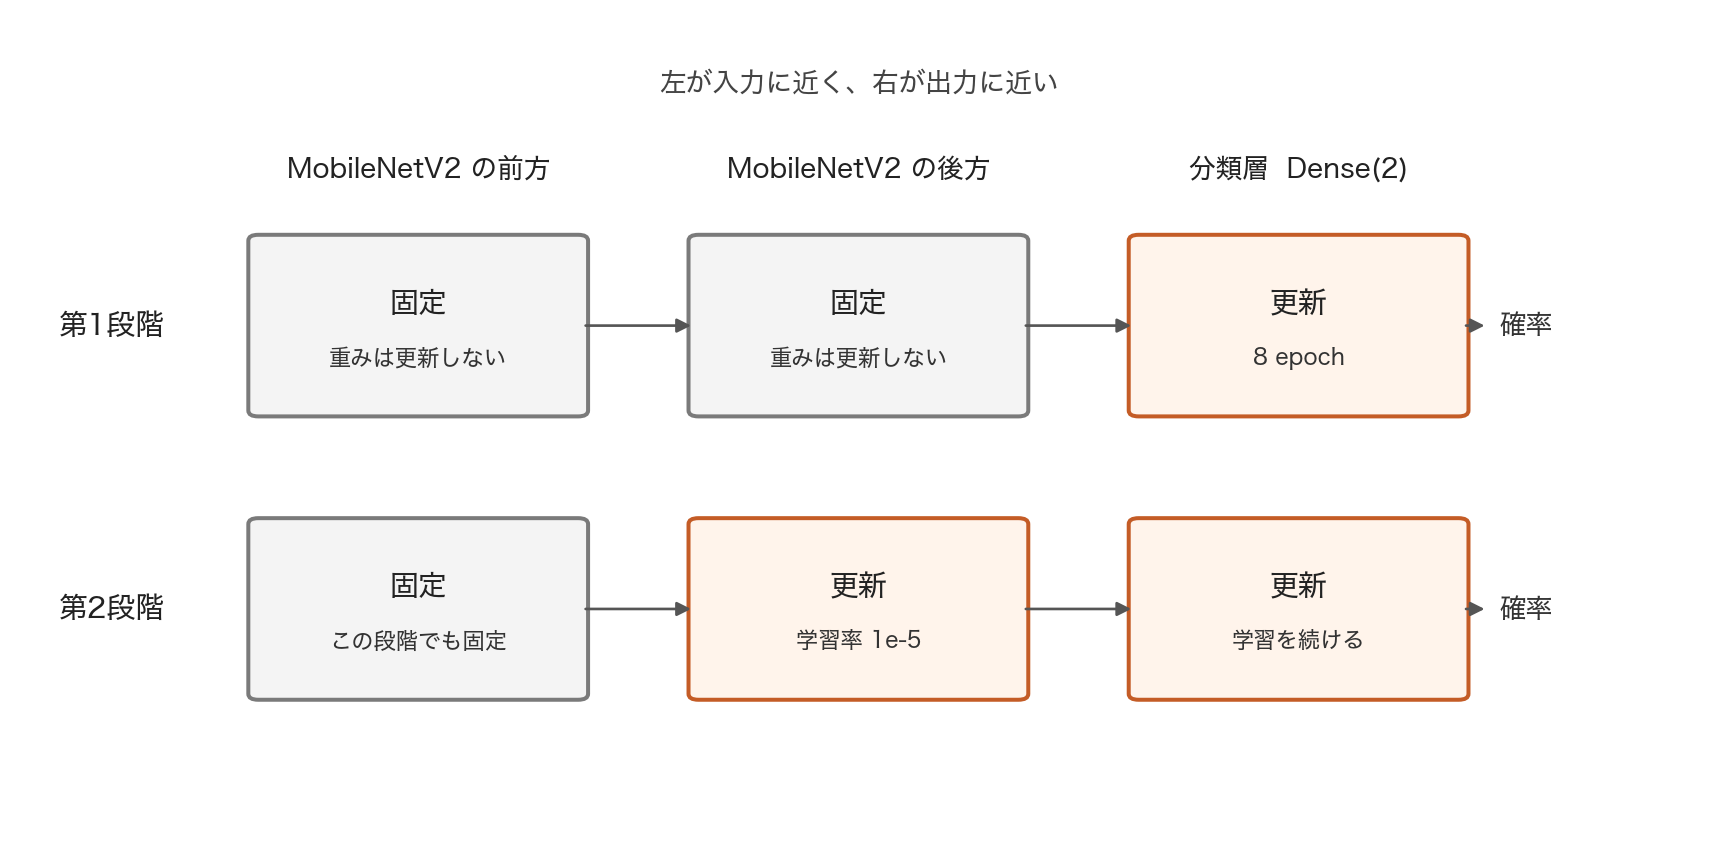

## 写真の置き方

Google Drive のマイドライブに次のように置いてください。
もちろんラーメンやカレー以外の写真でも問題ありません。

```
マイドライブ/data/
  ramen/    ... ラーメンの写真（jpg / png）
  curry/    ... カレーの写真（jpg / png）
```

ノートを開いたら Drive をマウントし、`マイドライブ/data` を読み込みます。
各クラス 50 枚以上あると安定しやすいです。角度や明るさを散らしてください。


In [ ]:
# 基本的なライブラリ
!pip install japanize_matplotlib
import numpy as np
import matplotlib.pyplot as plt
import japanize_matplotlib
from pandas import DataFrame
from pathlib import Path

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input

# 乱数のシードをセット
np.random.seed(20190222)
tf.random.set_seed(20190222)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# history出力用の関数
def plot_history(history, title):
    DataFrame({
        'train': history.history['acc'],
        'test': history.history['val_acc'],
    }).plot()
    plt.title(title + ' accuracy')
    plt.ylabel('accuracy')
    plt.show()
    DataFrame({
        'train': history.history['loss'],
        'test': history.history['val_loss'],
    }).plot()
    plt.title(title + ' loss')
    plt.ylabel('loss')
    plt.show()


In [ ]:
# Google Drive をマウントし、写真一覧を DataFrame にする
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/data'

rows = []
for folder in sorted(Path(DATA_DIR).iterdir()):
    if not folder.is_dir():
        continue
    for path in sorted(folder.iterdir()):
        if path.suffix.lower() not in {'.jpg', '.jpeg', '.png', '.webp'}:
            continue
        rows.append({'filepath': str(path), 'label': folder.name})

df = DataFrame(rows)
class_names = sorted(df['label'].unique())
df['label_index'] = df['label'].map({name: i for i, name in enumerate(class_names)})

# クラスごとに 0.8 を train、残りを test にする
train_df = df.groupby('label', group_keys=False).sample(frac=0.8, random_state=42)
test_df = df.drop(train_df.index)

print('クラス:', class_names)
print('全体:', len(df), ' train:', len(train_df), ' test:', len(test_df))
df.groupby('label').size()


In [ ]:
# train の写真を見て、ラベルを確認する
preview = train_df.sample(n=min(8, len(train_df)), random_state=0)

fig = plt.figure(figsize=(12, 3))
for i, row in enumerate(preview.itertuples()):
    image = tf.keras.utils.load_img(row.filepath, target_size=IMG_SIZE)
    subplot = fig.add_subplot(1, 8, i + 1)
    subplot.set_xticks([])
    subplot.set_yticks([])
    subplot.set_title(row.label)
    subplot.imshow(image)
plt.show()


## 前処理

MobileNetV2 は、ピクセルを 0〜1 にするのではなく、専用の `preprocess_input` で -1〜1 付近にそろえます。
train だけ、左右反転、少しの回転、ズーム、平行移動を加えます。


In [ ]:
# 学習中だけ画像を少し変形し、train と test の Dataset を作る
augment = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
], name='augment')

def decode(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, IMG_SIZE)
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    return image, label

def make_dataset(frame, training):
    ds = tf.data.Dataset.from_tensor_slices((
        frame['filepath'].tolist(),
        frame['label_index'].astype('int32').tolist(),
    ))
    if training:
        ds = ds.shuffle(len(frame), seed=42, reshuffle_each_iteration=True)
    ds = ds.map(decode, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(lambda image, label: (augment(image, training=True), label),
                    num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda image, label: (preprocess_input(image), label),
                num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
test_ds = make_dataset(test_df, training=False)


## モデル

ImageNet で学習済みの MobileNetV2 から、最後の1000クラス分類を外します。
畳み込み部分はいったん固定し、その上に自分の2クラス（ラーメン、カレー）を載せます。


In [ ]:
# モデルを定義
base = MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights='imagenet',
)
base.trainable = False  # まずは特徴抽出部を固定する

model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(name='gap'),
    layers.Dropout(0.3),
    layers.Dense(2, activation='softmax', name='softmax'),
])

model.summary()


In [ ]:
# モデルをコンパイル
# ラベルは 0, 1 の整数なので sparse_categorical_crossentropy
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['acc'],
)


In [ ]:
# 分類層だけ学習させる
history = model.fit(train_ds, validation_data=test_ds, epochs=8)
plot_history(history, '分類層')


## 微調整

分類層だけの学習では精度の向上が小さくなりやすいです。
MobileNetV2 の後方の層だけを学習可能に戻し、小さい学習率で追加の学習を行います。


In [ ]:
# 後ろの層だけ学習可能にする
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['acc'],
)

history_ft = model.fit(train_ds, validation_data=test_ds, epochs=4)
plot_history(history_ft, '微調整')


In [ ]:
# 分類層の学習と微調整を、1本のグラフにつなげて見る
acc = history.history['acc'] + history_ft.history['acc']
test_acc = history.history['val_acc'] + history_ft.history['val_acc']
loss = history.history['loss'] + history_ft.history['loss']
test_loss = history.history['val_loss'] + history_ft.history['val_loss']

DataFrame({'train': acc, 'test': test_acc}).plot()
plt.axvline(len(history.history['acc']) - 0.5, color='gray', linestyle='--')
plt.title('accuracy（破線のあとが微調整）')
plt.ylabel('accuracy')
plt.show()

DataFrame({'train': loss, 'test': test_loss}).plot()
plt.axvline(len(history.history['loss']) - 0.5, color='gray', linestyle='--')
plt.title('loss（破線のあとが微調整）')
plt.ylabel('loss')
plt.show()


In [ ]:
# test で精度を確認する
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print('test_loss: {}'.format(test_loss))
print('test_acc: {}'.format(test_acc))


## 正解した画像と、間違えた画像

test の写真から、正解を3枚、不正解を3枚見ます。


In [ ]:
# test の写真を、前処理前の色のまま確認する
correct = []
wrong = []
paths = test_df['filepath'].tolist()
labels = test_df['label_index'].astype(int).tolist()

for start in range(0, len(paths), BATCH_SIZE):
    batch_paths = paths[start:start + BATCH_SIZE]
    batch_labels = np.array(labels[start:start + BATCH_SIZE])
    images = np.stack([
        tf.keras.utils.img_to_array(tf.keras.utils.load_img(path, target_size=IMG_SIZE))
        for path in batch_paths
    ])
    probs = model.predict(preprocess_input(images), verbose=0)
    preds = np.argmax(probs, axis=1)
    for image, label, pred in zip(images, batch_labels, preds):
        item = (image, int(label), int(pred))
        if pred == label and len(correct) < 3:
            correct.append(item)
        elif pred != label and len(wrong) < 3:
            wrong.append(item)
    if len(correct) >= 3 and len(wrong) >= 3:
        break

def show_row(items, title):
    fig, axes = plt.subplots(1, 3, figsize=(9, 3))
    fig.suptitle(title)
    for ax, item in zip(axes, items):
        image, label, pred = item
        ax.imshow(image.astype('uint8'))
        ax.set_title('%s / %s' % (class_names[pred], class_names[label]))
        ax.set_xticks([])
        ax.set_yticks([])
    for ax in list(axes)[len(items):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

print('正解:', len(correct), '枚を表示')
if correct:
    show_row(correct, '正解した画像（予測 / 正解）')
else:
    print('test では正解がありませんでした。')

print('不正解:', len(wrong), '枚を表示')
if wrong:
    show_row(wrong, '間違えた画像（予測 / 正解）')
else:
    print('test ではミスがありませんでした。')


## 1枚を予測する

`IMAGE_PATH` を予測したい写真のパスに変えて実行してください。


In [ ]:
# 1枚の写真で予測する。パスは Drive 上の写真に変えてよい
IMAGE_PATH = DATA_DIR + '/ramen/001.jpg'

image = tf.keras.utils.load_img(IMAGE_PATH, target_size=IMG_SIZE)
array = tf.keras.utils.img_to_array(image)
prob = model.predict(preprocess_input(array[None, ...]), verbose=0)[0]
pred = int(np.argmax(prob))

plt.figure(figsize=(3, 3))
plt.imshow(image)
plt.title(class_names[pred])
plt.axis('off')
plt.show()

print('予測:', class_names[pred])
for name, p in zip(class_names, prob):
    print('  {}: {:.3f}'.format(name, p))
